# YSL merFISH Projections

## Environment Setup

Install software from pip, apt, and Github.  Load modules, configure workspace settings.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Environment Setup: everything now handled inside zmap-tools
#!pip -q install "git+https://github.com/WagnerLabUCSF/zmap-tools.git"
!pip -q install igraph leidenalg zmap-tools

import zmap
import scanpy as sc

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 141.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 164.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.1/102.1 kB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 176.1/176.1 kB 24.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.5/18.5 MB 143.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 106.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 159.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 376.9/376.9 kB 53.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 98.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225

In [ ]:
!pip list

Package                               Version
------------------------------------- ------------------
absl-py                               1.4.0
accelerate                            1.14.0
access                                1.1.10.post3
adjustText                            1.4.0
affine                                2.4.0
aiofiles                              25.1.0
aiohappyeyeballs                      2.7.1
aiohttp                               3.14.1
aiosignal                             1.4.0
aiosqlite                             0.22.1
alabaster                             1.0.0
albucore                              0.0.24
albumentations                        2.0.8
ale-py                                0.12.0
altair                                5.5.0
anndata                               0.12.18
annotated-doc                         0.0.4
annotated-types                       0.7.0
antlr4-python3-runtime                4.9.3
anyio                                 4.14.2
a

In [ ]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Load YSL h5ad

In [ ]:
# Load YSL query dataset
base_path='/content/drive/MyDrive/Colab Notebooks/Haley/YSL/'
adata = sc.read(base_path+'YSL-subset_pp_norm_processed.h5ad')

## Load merFish h5ad

In [ ]:
adata_mf1 = sc.read('/content/drive/MyDrive/Colab Notebooks/WanSchier2026/weMERFISH_measured_B_75p_E1.h5ad')
adata_mf2 = sc.read('/content/drive/MyDrive/Colab Notebooks/WanSchier2026/weMERFISH_measured_B_75p_E2.h5ad')

adata_mf = adata_mf1.concatenate(adata_mf2)
adata_mf.layers['raw_nolog'] = adata_mf.X.copy()
adata_mf_ysl = adata_mf[adata_mf.obs['clusters']=='YSL']


/tmp/ipykernel_222/3238209650.py:4: FutureWarning: The method concatenate is deprecated and will be removed in the future. Use anndata.concat instead of AnnData.concatenate. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata_mf = adata_mf1.concatenate(adata_mf2)


## Plotting merFish spatial data

In [ ]:
adata_mf

AnnData object with n_obs × n_vars = 36541 × 495
    obs: 'global_z', 'global_x', 'global_y', 'cellvol', 'stage', 'batch', 'cell_id', 'blank_ct', 'n_counts', 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'leiden', 'clusters', 'germlayer', 'type', 'phi', 'theta'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'mean', 'std'
    obsm: 'X_raw', 'X_umap', 'global_sphere', 'spatial', 'spatial_overlaid', 'sphere_dorsal', 'sphere_side', 'sphere_top'
    layers: 'spliced', 'unspliced', 'raw_nolog'

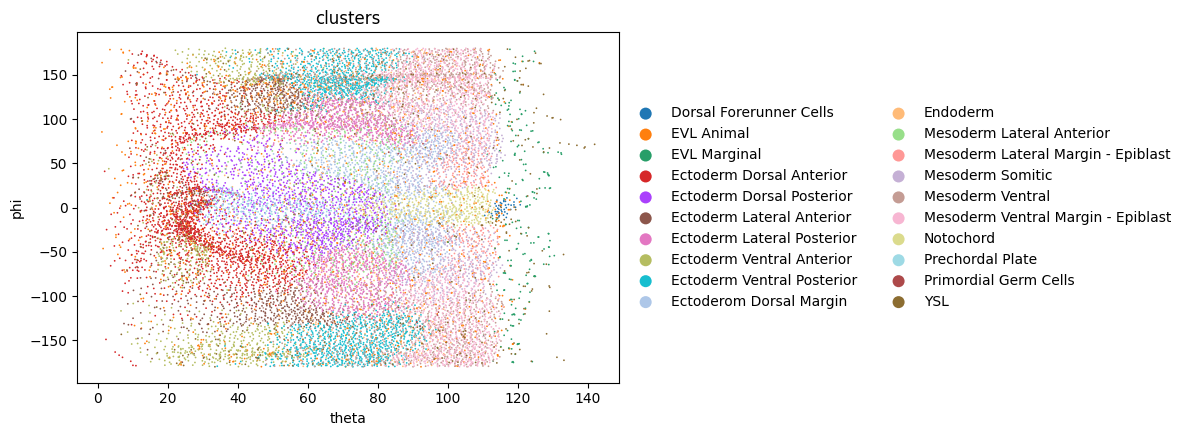

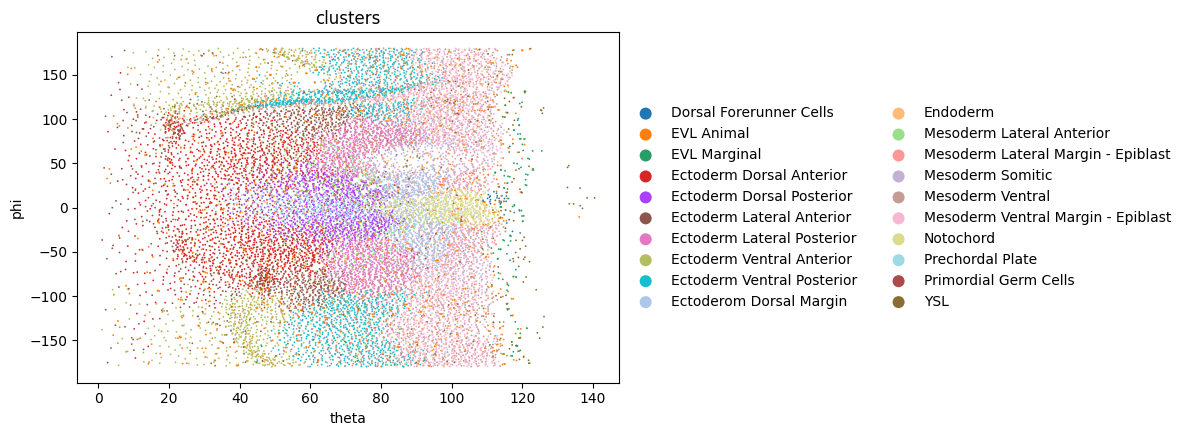

In [ ]:
sc.pl.scatter(adata_mf1, x='theta', y='phi', color='clusters')
sc.pl.scatter(adata_mf2, x='theta', y='phi', color='clusters')

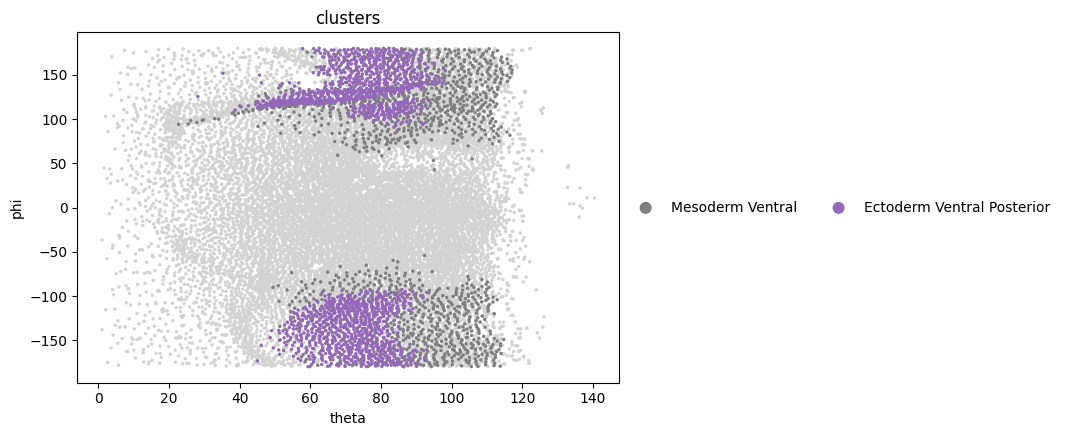

In [ ]:
sc.pl.scatter(adata_mf2,
              x='theta', y='phi',
              color='clusters',
              groups=['Mesoderm Ventral', 'Ectoderm Ventral Posterior'],
              palette='tab10',
              size=25)


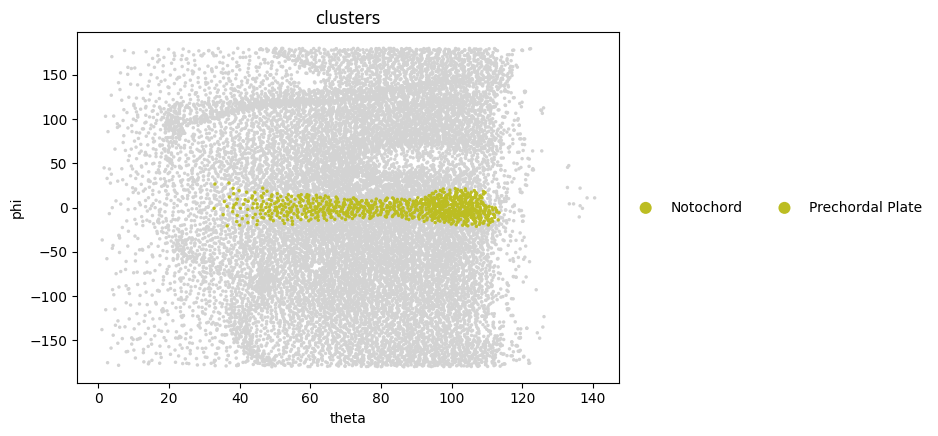

In [ ]:
sc.pl.scatter(adata_mf2,
              x='theta', y='phi',
              color='clusters',
              groups=['Notochord', 'Prechordal Plate'],
              palette='tab10',
              size=25)


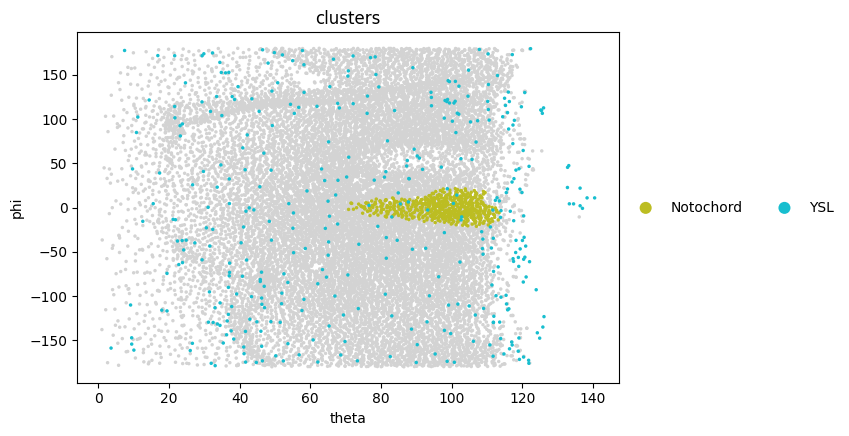

In [ ]:
sc.pl.scatter(adata_mf2,
              x='theta', y='phi',
              color='clusters',
              groups=['Notochord', 'YSL'],
              palette='tab10',
              size=25)



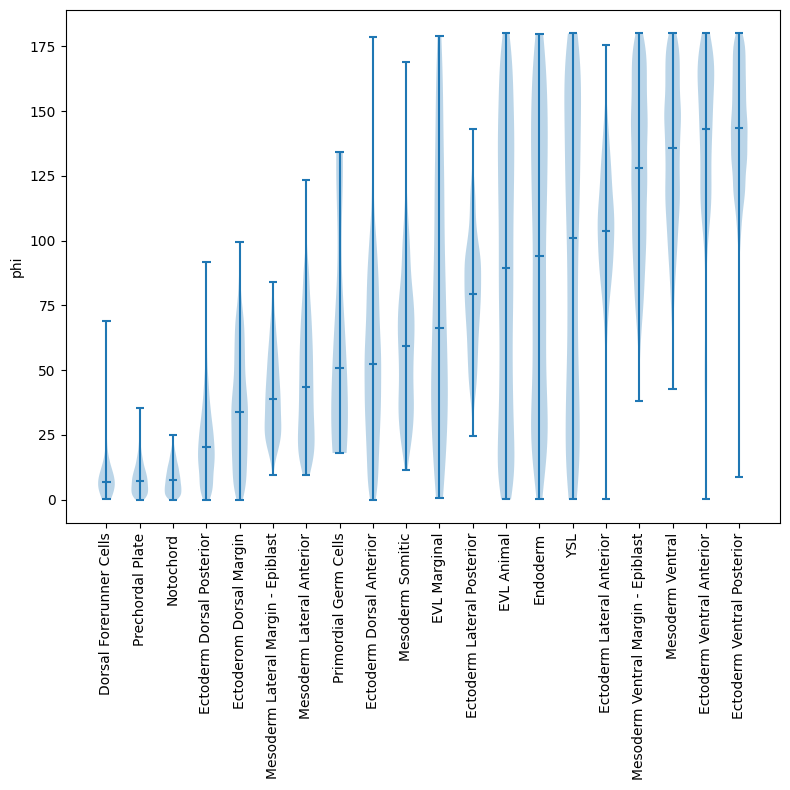

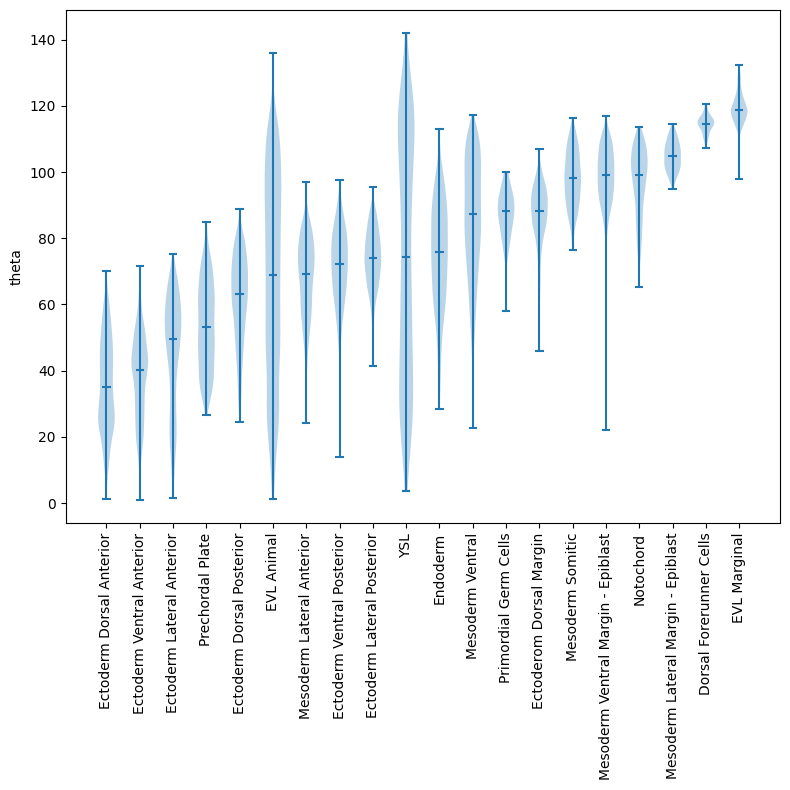

In [ ]:
def plot_spatial_violin(
    adata,
    cluster_col='clusters',
    spatial_col='phi',
    sort_by_median=False,
    #ylim=(0, 200),
    figsize=(8, 8),
):
    tissues = adata.obs[cluster_col].dropna().unique().tolist()

    if sort_by_median:
        tissues = sorted(
            tissues,
            key=lambda x: np.abs(
                adata.obs.loc[adata.obs[cluster_col] == x, spatial_col]
            ).median()
        )

    data = [
        np.abs(adata.obs.loc[adata.obs[cluster_col] == tissue, spatial_col].dropna())
        for tissue in tissues
    ]

    fig, ax = plt.subplots(figsize=figsize)

    ax.violinplot(data, showmedians=True)
    ax.set_xticks(range(1, len(tissues) + 1))
    ax.set_xticklabels(tissues, rotation=90)
    ax.set_ylabel(spatial_col)
    #ax.set_ylim(*ylim)

    plt.tight_layout()
    return fig, ax


In [ ]:
f1,_ = plot_spatial_violin(adata_mf, spatial_col='phi', sort_by_median=True)
f2,_ = plot_spatial_violin(adata_mf, spatial_col='theta', sort_by_median=True)

f1.savefig(base_path+'figs/'+'merFISH_phi_vs_clusters.png', dpi=200, bbox_inches="tight")
f2.savefig(base_path+'figs/'+'merFISH_theta_vs_clusters.png', dpi=200, bbox_inches="tight")


## Manual embedding of the merFish data

In [ ]:
import harmonypy

adata_mf.X = adata_mf.layers['raw_nolog'].copy(); #del adata_mf.uns['log1p']
sc.pp.normalize_total(adata_mf)
sc.pp.log1p(adata_mf)
sc.pp.scale(adata_mf)
sc.tl.pca(adata_mf)
adata_mf.obsm["X_pca_harmony"] = harmonypy.run_harmony(adata_mf.obsm["X_pca"], adata_mf.obs, "batch").Z_corr
sc.pp.neighbors(adata_mf, n_neighbors=20, use_rep = "X_pca_harmony")#, n_pcs=50)
sc.tl.umap(adata_mf,random_state=9)

2026-09-22 18:45:07,547 - harmonypy - INFO - Running Harmony
INFO:harmonypy:Running Harmony
2026-09-22 18:45:07,550 - harmonypy - INFO -   Parameters:
INFO:harmonypy:  Parameters:
2026-09-22 18:45:07,551 - harmonypy - INFO -     max_iter_harmony: 10
INFO:harmonypy:    max_iter_harmony: 10
2026-09-22 18:45:07,553 - harmonypy - INFO -     max_iter_kmeans: 4
INFO:harmonypy:    max_iter_kmeans: 4
2026-09-22 18:45:07,554 - harmonypy - INFO -     epsilon_cluster: 0.001
INFO:harmonypy:    epsilon_cluster: 0.001
2026-09-22 18:45:07,555 - harmonypy - INFO -     epsilon_harmony: 0.01
INFO:harmonypy:    epsilon_harmony: 0.01
2026-09-22 18:45:07,556 - harmonypy - INFO -     nclust: 100
INFO:harmonypy:    nclust: 100
2026-09-22 18:45:07,558 - harmonypy - INFO -     block_size: 0.05
INFO:harmonypy:    block_size: 0.05
2026-09-22 18:45:07,559 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
INFO:harmonypy:    lamb: dynamic (alpha=0.2)
2026-09-22 18:45:07,560 - harmonypy - INFO -     theta: [2. 2.]


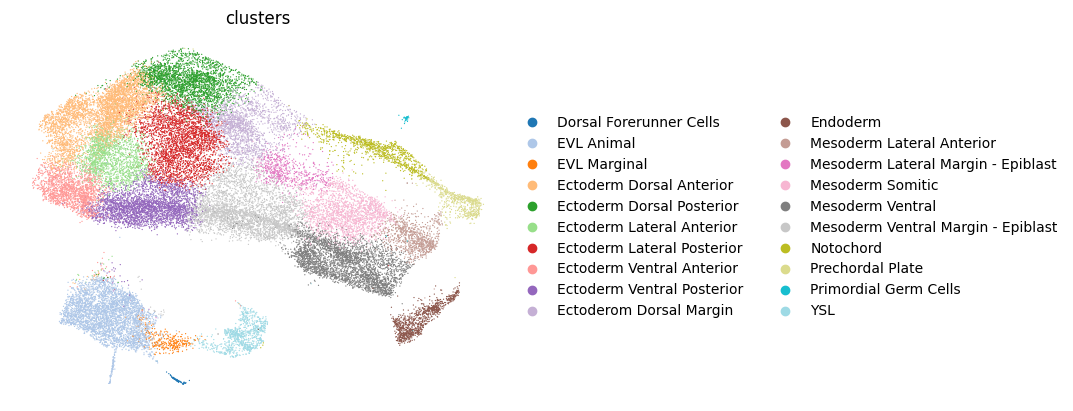

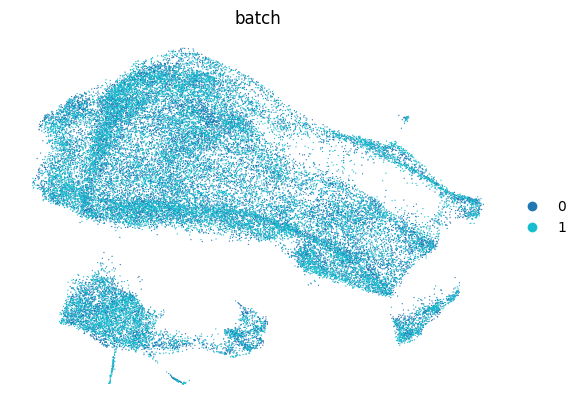

In [ ]:
sc.pl.umap(adata_mf, color=['clusters'], palette='tab20', frameon=False)
sc.pl.umap(adata_mf, color=['batch'], palette='tab10', frameon=False)

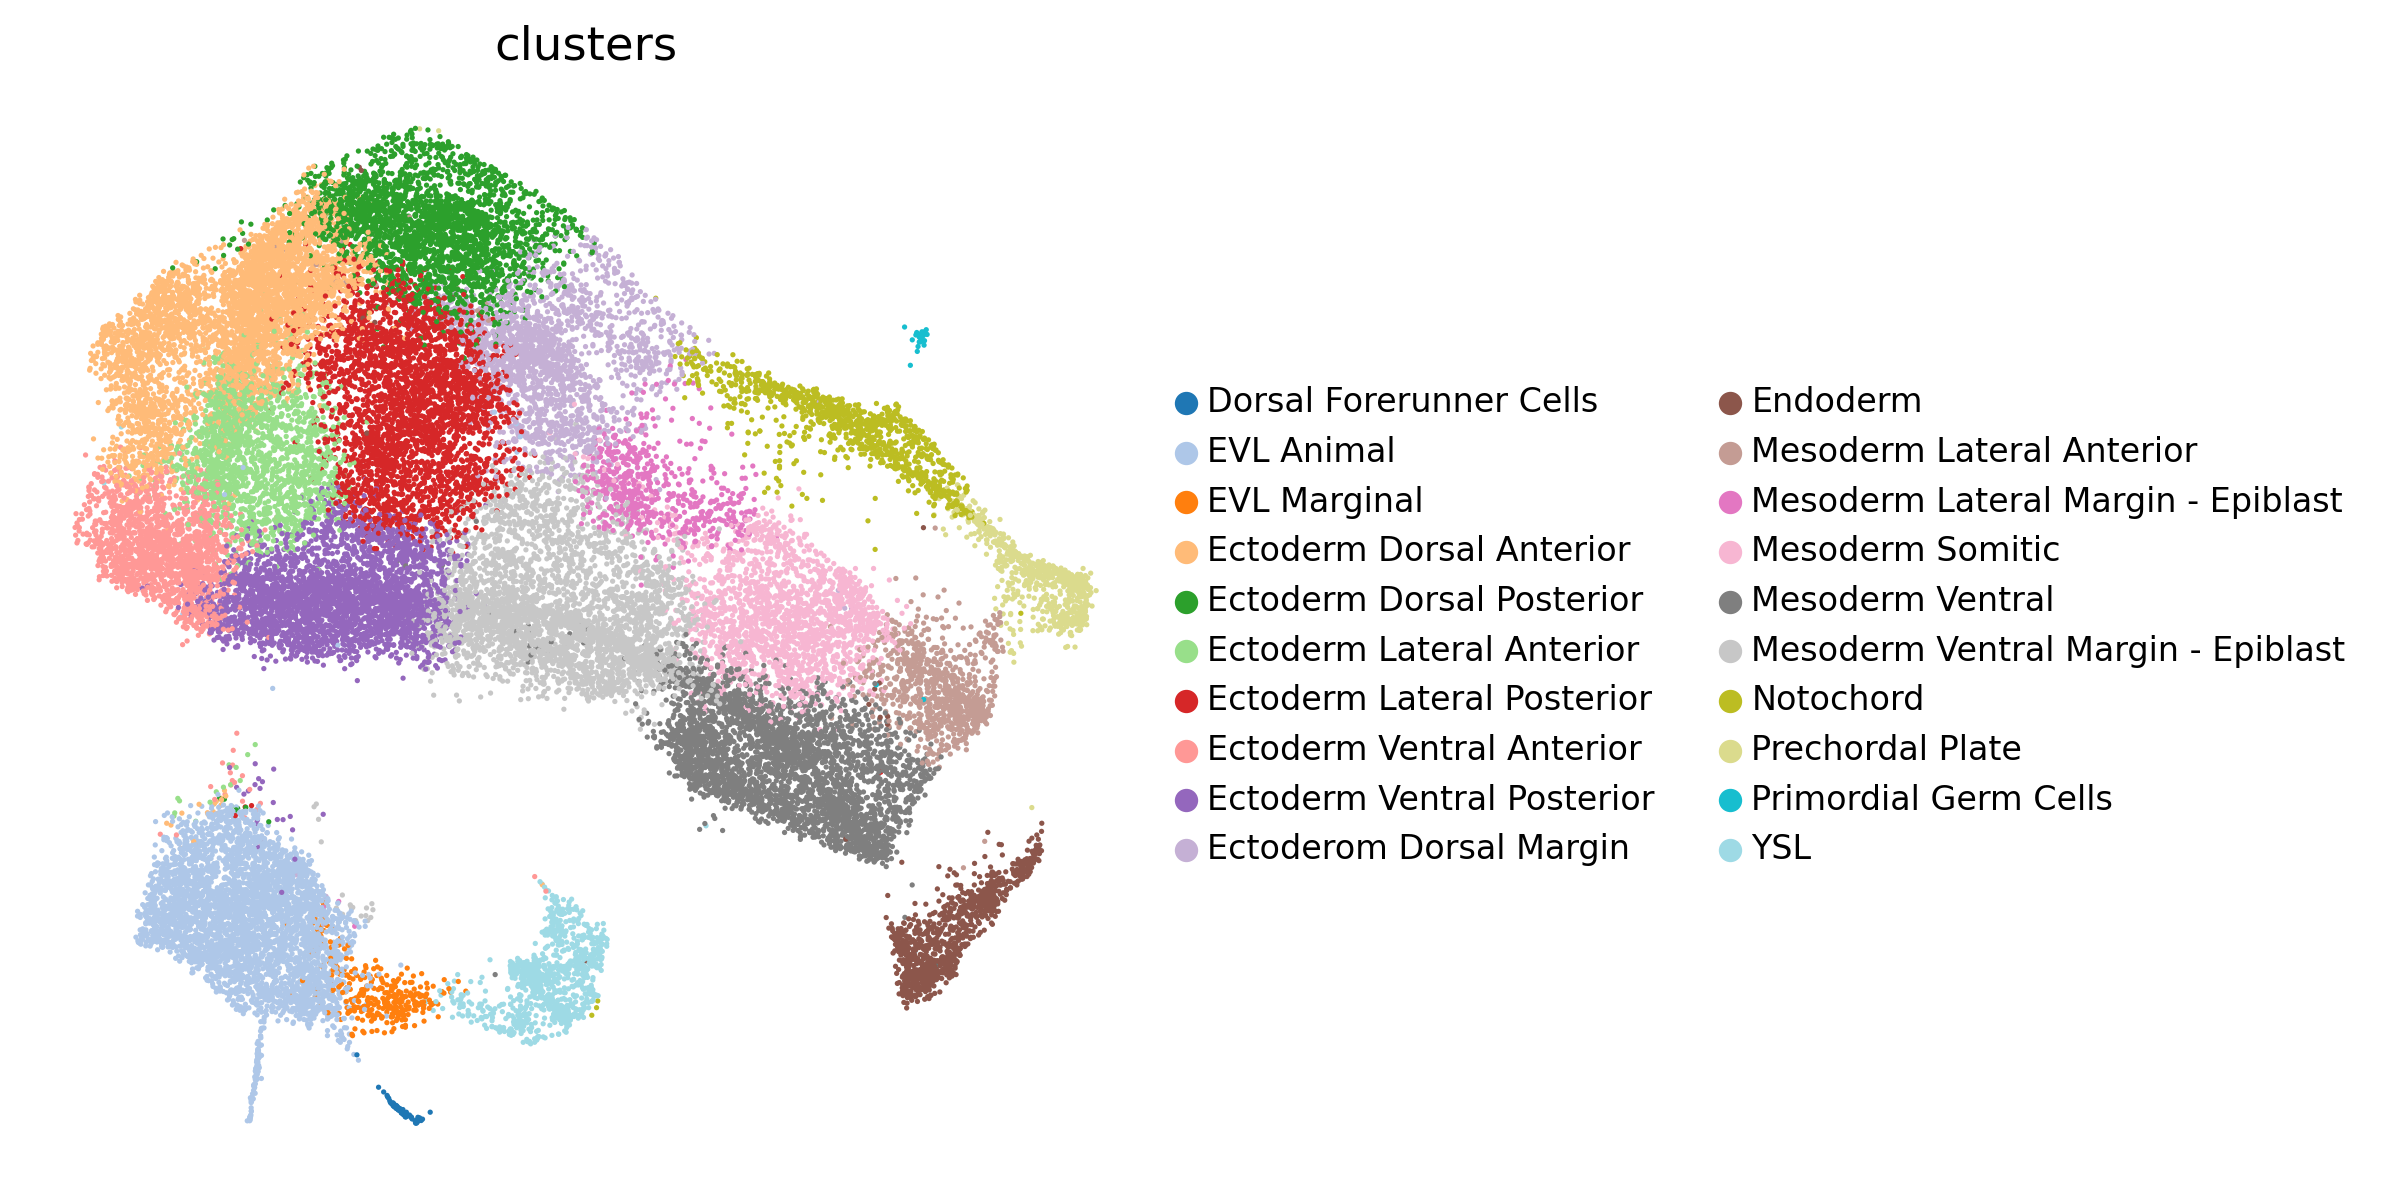

In [ ]:
sc.set_figure_params(figsize=(6, 6), dpi=120)

f = sc.pl.umap(adata_mf,
               color='clusters',
               palette='tab20',
               s=10, frameon=False, legend_fontsize=10,
               show=False,
               return_fig=True)

f.savefig(base_path+'figs/'+'MERFISH_umap_celltype.pdf', bbox_inches="tight")

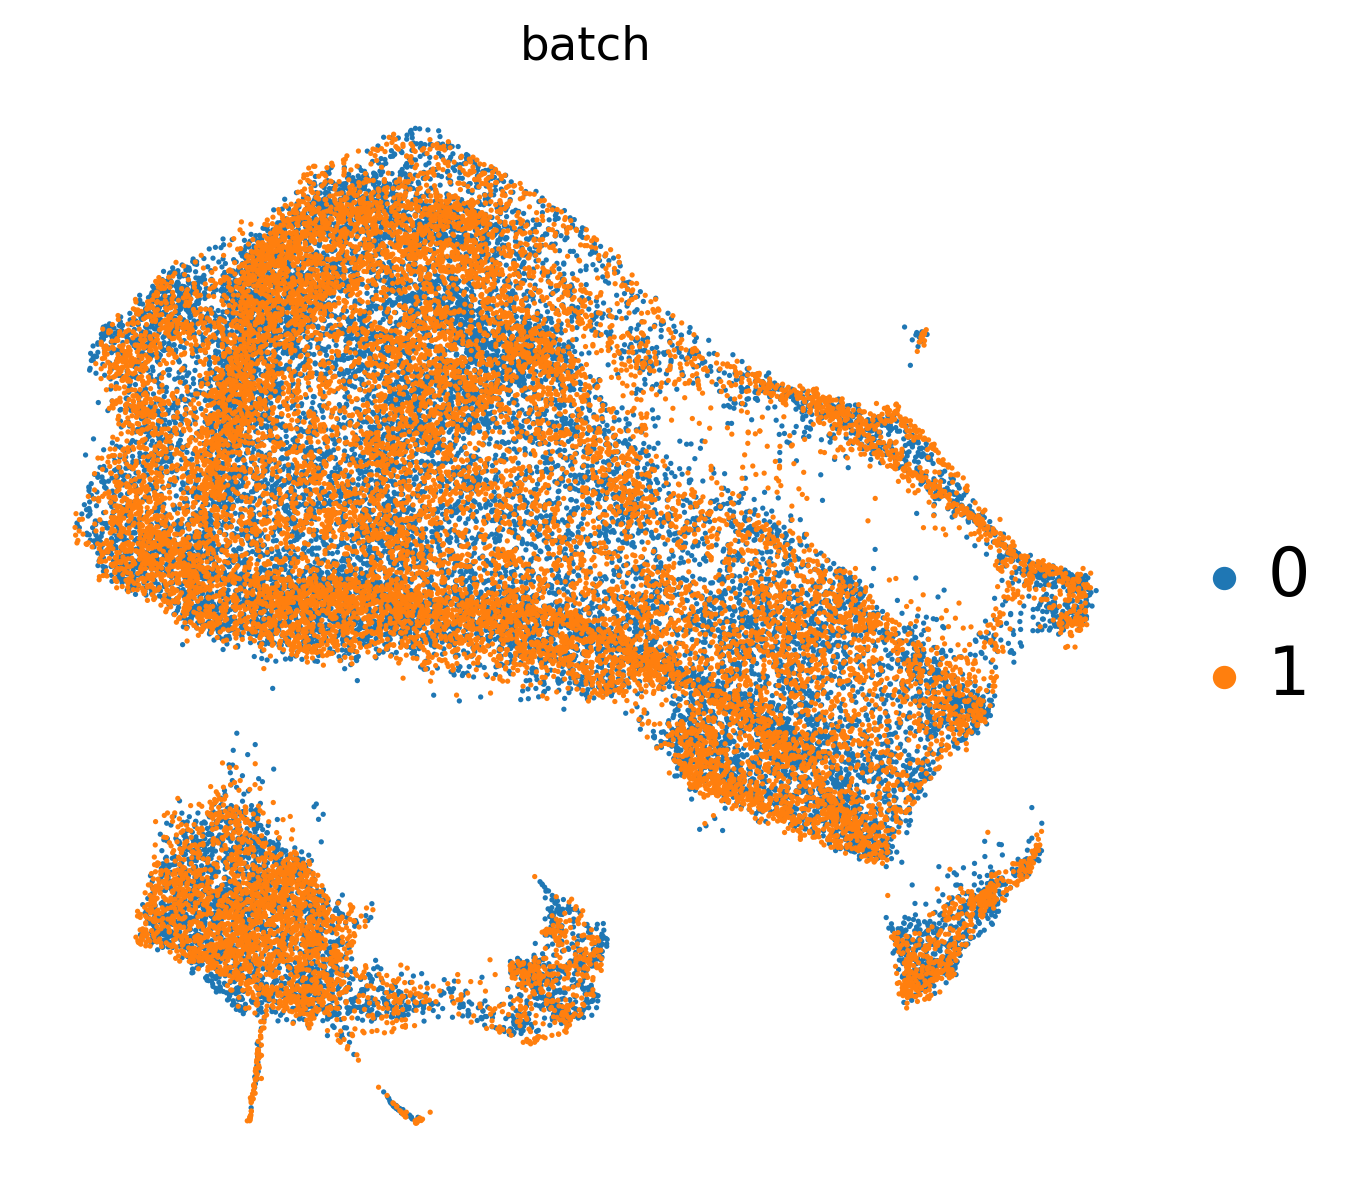

In [ ]:
sc.set_figure_params(figsize=(6, 6), dpi=120)

f = sc.pl.umap(adata_mf,
               color='batch',
               palette=['#1f77b4','#ff7f0e'],
               s=10, frameon=False, legend_fontsize=20,
               show=False, sort_order=True,
               return_fig=True)

f.savefig(base_path+'figs/'+'MERFISH_umap_batch.pdf', bbox_inches="tight")

In [ ]:
adata_mf.obs['phi_abs'] = adata_mf.obs['phi'].abs()

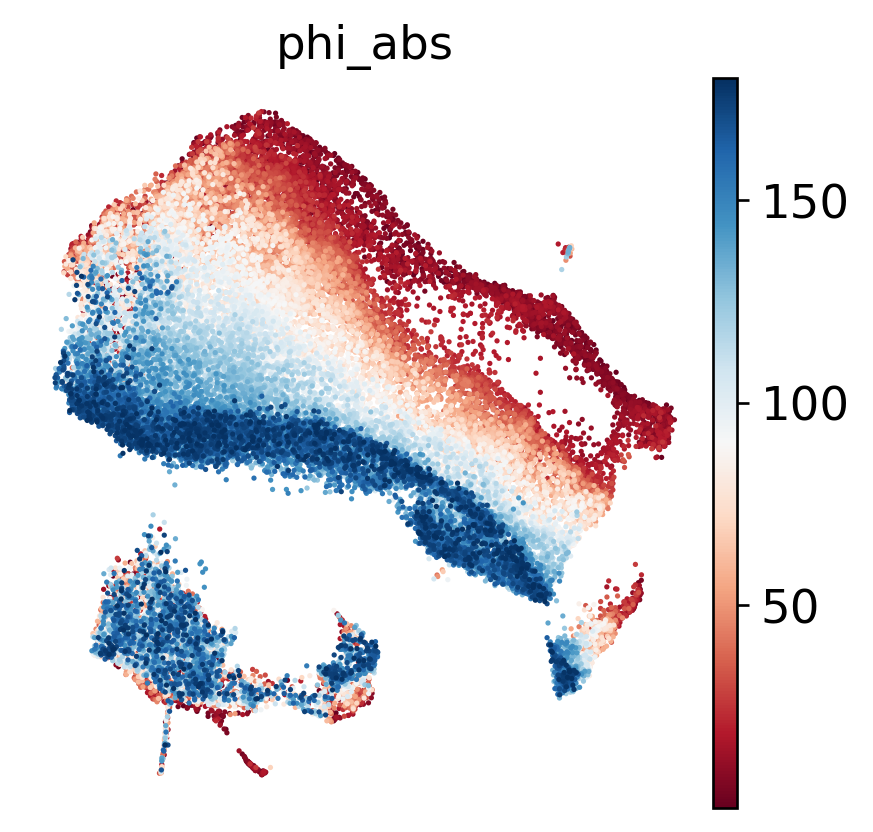

In [ ]:
sc.set_figure_params(figsize=(4, 4), dpi=120)

f = sc.pl.umap(adata_mf,
               color='phi_abs',
               cmap='RdBu',
               s=10, frameon=False, legend_fontsize=10,
               show=False,
               return_fig=True)

f.savefig(base_path+'figs/'+'MERFISH_umap_phi.pdf', bbox_inches="tight")

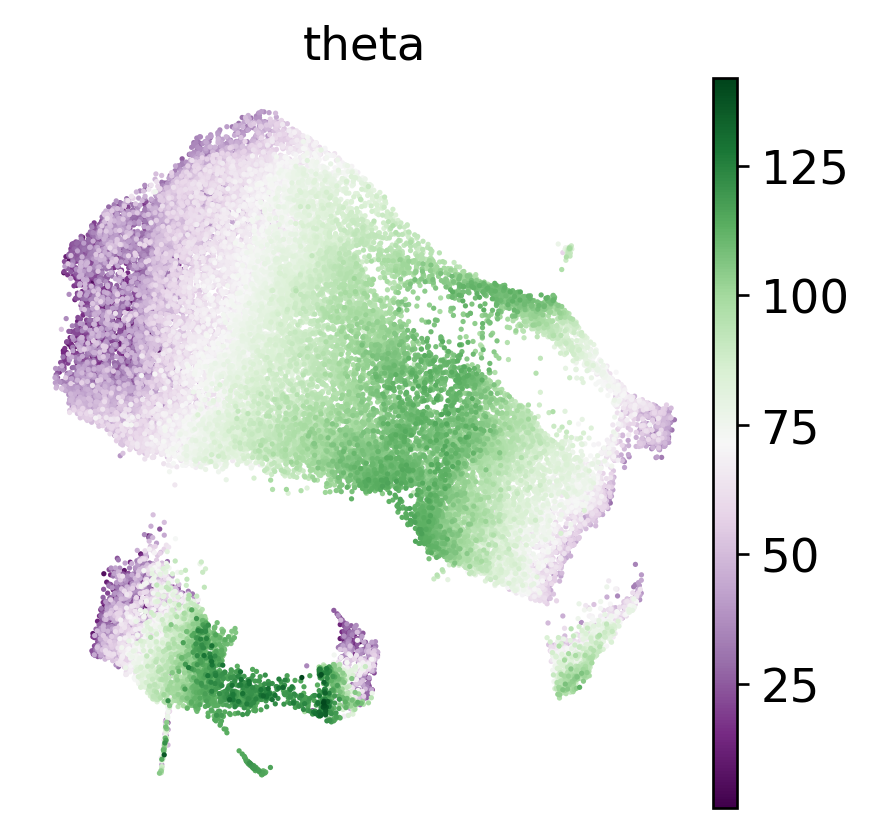

In [ ]:
sc.set_figure_params(figsize=(4, 4), dpi=120)

f = sc.pl.umap(adata_mf,
               color='theta',
               cmap='PRGn',
               s=10, frameon=False, legend_fontsize=10,
               show=False,
               return_fig=True)

f.savefig(base_path+'figs/'+'MERFISH_umap_theta.pdf', bbox_inches="tight")

## merFISH knn transfer pipeline

In [ ]:
"""
Transfer cluster labels and numeric coordinates (like phi/theta) from a MERFISH
reference onto a Parse query by kNN in a shared PCA space.

Numeric keys can be plain (linear) or circular. Circular keys are angles, so they
get averaged around the circle instead of straight up (keeps the wrap-around
seam (e.g. -180 and +180) from dragging values toward the middle).
"""

import logging
import warnings
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import harmonypy
from scipy.special import entr
from sklearn.neighbors import NearestNeighbors
from sklearn.isotonic import IsotonicRegression

logging.getLogger("harmonypy").setLevel(logging.WARNING)


def _as_list(x):
    """None -> [], a bare string -> [string], anything else -> list(x)."""
    if x is None:
        return []
    return [x] if isinstance(x, str) else list(x)


def build_reference(refs, num_keys, n_pcs=30, theta=2.0, target_sum=1e4,
                    circular_keys=None, batch_key="batch", ref_raw_layer=None):
    """Build the reference embedding the query gets mapped into.

    refs can be one AnnData or a list of them. Harmony only runs when there's
    actually more than one batch to integrate - either a list of references, or a
    single reference whose `batch_key` column has several levels. Otherwise it's
    skipped and we just use plain PCA, so a clean single reference stays clean.

    Set ref_raw_layer if .X isn't raw counts: we normalize + log it here, so
    handing in already log/scaled .X would produce NaNs and break PCA.
    """
    num_keys = _as_list(num_keys)
    circ_set = set(_as_list(circular_keys))
    refs_list = [r.copy() for r in ([refs] if isinstance(refs, ad.AnnData) else refs)]

    for r in refs_list:
        if ref_raw_layer is not None:
            r.X = r.layers[ref_raw_layer].copy()
        for key in num_keys:                       # drop sign on linear coords only, never angles
            if key not in circ_set:
                r.obs[key] = r.obs[key].abs()

    if len(refs_list) > 1:                          # tag each input as its own batch, then merge
        for i, r in enumerate(refs_list):
            r.obs[batch_key] = f"b{i}"
        ref = ad.concat(refs_list, join="inner", index_unique="-")
    else:
        ref = refs_list[0]

    sc.pp.normalize_total(ref, target_sum=target_sum)
    sc.pp.log1p(ref)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        sc.pp.scale(ref)

    ref.uns["ref_genes"] = list(ref.var_names)
    ref.uns["target_sum"] = target_sum
    sc.tl.pca(ref, n_comps=n_pcs, zero_center=True, svd_solver="arpack")

    use_harmony = batch_key in ref.obs.columns and ref.obs[batch_key].nunique() > 1
    if use_harmony:
        Z = harmonypy.run_harmony(ref.obsm["X_pca"], ref.obs, batch_key, theta=theta).Z_corr.T
        ref.obsm["X_pca_harmony"] = Z if Z.shape[0] == ref.n_obs else Z.T
    else:
        ref.obsm["X_pca_harmony"] = ref.obsm["X_pca"].copy()   # nothing to correct

    sc.pp.neighbors(ref, use_rep="X_pca_harmony")
    sc.tl.umap(ref)

    print(f"Reference: {ref.n_obs:,} cells | {ref.n_vars} genes | "
          f"Harmony {'on' if use_harmony else 'off'}")
    return ref


def preprocess_query(query, ref, raw_layer="raw"):
    """Normalize/scale the query the same way as the reference and match gene order."""
    ref_genes = ref.uns["ref_genes"]
    missing = set(ref_genes) - set(query.var_names)
    if missing:
        print(f"WARNING: {len(missing)} reference genes missing from query, zero-filled")

    query = query.copy()
    query.X = query.layers[raw_layer]

    for msg in ("adata.X seems to be already log-transformed",
                "Some cells have zero counts", "Only some AnnData objects have"):
        warnings.filterwarnings("ignore", message=msg)

    sc.pp.normalize_total(query, target_sum=ref.uns["target_sum"])
    sc.pp.log1p(query)

    # scale only the genes we actually have (scaling an all-zero column gives NaN),
    # then pad the missing ones back as zeros so the gene order matches the reference
    query = query[:, [g for g in ref_genes if g in query.var_names]].copy()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        sc.pp.scale(query)

    if missing:
        filler = ad.AnnData(np.zeros((query.n_obs, len(missing))),
                            obs=query.obs, var=pd.DataFrame(index=sorted(missing)))
        query = ad.concat([query, filler], axis=1)
    query = query[:, ref_genes].copy()

    print(f"Query: {query.n_obs:,} cells | {query.n_vars} genes")
    return query


def project_query(query, ref):
    """Project the query into the reference PCA space -> (n_query, n_pcs)."""
    X = query.X if isinstance(query.X, np.ndarray) else query.X.toarray()
    return X @ ref.varm["PCs"]


def _fit_calibrator(nn, coords, true_vals, k, method):
    """Learn a fix for kNN range-compression, straight from the reference.

    We run the same kNN regressor leave-one-out on the reference (predict each cell
    from its neighbors, minus itself), which reproduces the same edge clipping on
    data where we know the truth. Then we fit a map from those compressed
    predictions back to the real values and hand it back to apply to the query.

    isotonic        - monotone fit, corrects the edges best but can band a smooth field
    isotonic_smooth - same, lightly smoothed so it doesn't quantize into rings
    linear          - plain slope/intercept, smoothest but only a global rescale
    """
    d, idx = nn.kneighbors(coords, n_neighbors=k + 1)
    d, idx = d[:, 1:], idx[:, 1:]                          # drop self (the zero-distance hit)
    sigma = np.median(d, axis=1, keepdims=True) + 1e-10
    w = np.exp(-0.5 * (d / sigma) ** 2)
    w /= w.sum(axis=1, keepdims=True)
    pred = (w * true_vals[idx]).sum(axis=1)
    lo, hi = float(true_vals.min()), float(true_vals.max())

    if method == "isotonic":
        return IsotonicRegression(out_of_bounds="clip", y_min=lo, y_max=hi).fit(pred, true_vals).transform
    if method == "isotonic_smooth":
        from scipy.ndimage import gaussian_filter1d
        iso = IsotonicRegression(out_of_bounds="clip", y_min=lo, y_max=hi).fit(pred, true_vals)
        grid = np.linspace(pred.min(), pred.max(), 400)
        curve = np.maximum.accumulate(gaussian_filter1d(iso.transform(grid), sigma=8.0))
        return lambda x: np.clip(np.interp(np.asarray(x, float), grid, curve), lo, hi)
    if method == "linear":
        a, b = np.polyfit(pred, true_vals, 1)
        return lambda x: np.clip(a * np.asarray(x) + b, lo, hi)
    raise ValueError("calibrate_method must be 'isotonic', 'isotonic_smooth', or 'linear'")


def transfer(query_pca, ref, cat_keys, num_keys, k=20,
             circular_keys=None, circular_period=2.0 * np.pi, circular_range="0_to_P",
             fold_keys=None, fold_axis=0.0,
             calibrate_keys=None, calibrate_method="isotonic"):
    """Vote each query cell's labels/coords from its k nearest reference neighbors.

    circular_keys    keys (subset of num_keys) that are angles -> averaged on the circle.
    circular_period  scalar or {key: period}. 2*pi for radians, 360 for degrees.
    circular_range   "0_to_P" gives [0, period); "centered" gives [-period/2, period/2).
    fold_keys        circular keys to ALSO mirror onto a half circle, saved as {key}_folded.
    fold_axis        scalar or {key: axis}: where the mirror line sits (same units as the key).
    calibrate_keys   linear keys to de-compress with leave-one-out calibration. The fixed
                     value lands in {key}, the raw one is kept in {key}_raw.
    calibrate_method "isotonic", "isotonic_smooth", or "linear".
    """
    cat_keys = _as_list(cat_keys)
    num_keys = _as_list(num_keys)
    circ_set = set(_as_list(circular_keys))
    fold_set = set(_as_list(fold_keys))
    calib_set = set(_as_list(calibrate_keys))

    if circ_set - set(num_keys):
        raise ValueError(f"circular_keys not in num_keys: {sorted(circ_set - set(num_keys))}")
    if fold_set - circ_set:
        raise ValueError(f"fold_keys must be circular keys: {sorted(fold_set - circ_set)}")
    bad = calib_set - (set(num_keys) - circ_set)
    if bad:
        raise ValueError(f"calibrate_keys must be linear num_keys, not circular: {sorted(bad)}")
    if circular_range not in ("0_to_P", "centered"):
        raise ValueError("circular_range must be '0_to_P' or 'centered'")

    # per-key period and fold axis, whether passed as a scalar or a dict
    period = {key: float(circular_period if np.isscalar(circular_period)
                         else circular_period.get(key, 2.0 * np.pi)) for key in circ_set}
    axis = {key: float(fold_axis if np.isscalar(fold_axis)
                       else fold_axis.get(key, 0.0)) for key in fold_set}

    # find neighbors and turn distances into normalized Gaussian weights
    nn = NearestNeighbors(n_neighbors=k, metric="euclidean", n_jobs=-1).fit(ref.obsm["X_pca_harmony"])
    dist, idx = nn.kneighbors(query_pca)
    sigma = np.median(dist, axis=1, keepdims=True) + 1e-10
    w = np.exp(-0.5 * (dist / sigma) ** 2)
    w /= w.sum(axis=1, keepdims=True)

    result = {}

    # categorical: weighted vote, plus a normalized-entropy uncertainty (0 = unanimous)
    for key in cat_keys:
        labels = ref.obs[key].values
        options = np.unique(labels)
        votes = np.column_stack([(w * (labels[idx] == c)).sum(axis=1) for c in options])
        result[key] = options[votes.argmax(axis=1)]
        result[f"{key}_uncertainty"] = entr(votes + 1e-10).sum(axis=1) / np.log(max(len(options), 2))

    # numeric: circular average for angles, weighted mean (optionally calibrated) otherwise
    for key in num_keys:
        nbr = np.asarray(ref.obs[key].values, float)[idx]    # neighbor values, (n_query, k)

        if key in circ_set:
            scale = 2.0 * np.pi / period[key]
            s = (w * np.sin(nbr * scale)).sum(axis=1)
            c = (w * np.cos(nbr * scale)).sum(axis=1)
            ang = np.mod(np.arctan2(s, c), 2.0 * np.pi) / scale          # back into [0, period)
            if circular_range == "centered":
                ang = np.mod(ang + period[key] / 2, period[key]) - period[key] / 2
            result[key] = ang
            result[f"{key}_uncertainty"] = 1.0 - np.sqrt(s ** 2 + c ** 2)  # 0 = tight, 1 = scattered
            if key in fold_set:                                          # mirror onto a half circle
                P, ax = period[key], axis[key]
                result[f"{key}_folded"] = np.abs(np.mod(ang - ax + P / 2, P) - P / 2)
        else:
            pred = (w * nbr).sum(axis=1)
            if key in calib_set:
                calibrate = _fit_calibrator(nn, ref.obsm["X_pca_harmony"],
                                            np.asarray(ref.obs[key].values, float), k, calibrate_method)
                result[f"{key}_raw"] = pred          # keep the uncalibrated version around
                result[key] = calibrate(pred)
            else:
                result[key] = pred

    return pd.DataFrame(result)


def run_pipeline(refs, query, cat_keys, num_keys, raw_layer="raw",
                 n_pcs=30, k=20, theta=2.0, batch_key="batch", ref_raw_layer=None,
                 circular_keys=None, circular_period=2.0 * np.pi, circular_range="0_to_P",
                 fold_keys=None, fold_axis=0.0,
                 calibrate_keys=None, calibrate_method="isotonic"):
    """Build the reference, map the query in, and write the results onto query.obs.

    refs           one AnnData, or a list to integrate with Harmony (see build_reference).
    ref_raw_layer  layer with raw counts in the reference; leave None if .X is already raw.
    """
    ref = build_reference(refs, num_keys, n_pcs, theta,
                          circular_keys=circular_keys, batch_key=batch_key,
                          ref_raw_layer=ref_raw_layer)
    query_proc = preprocess_query(query, ref, raw_layer=raw_layer)
    query_pca = project_query(query_proc, ref)
    results = transfer(query_pca, ref, cat_keys, num_keys, k,
                       circular_keys=circular_keys, circular_period=circular_period,
                       circular_range=circular_range, fold_keys=fold_keys, fold_axis=fold_axis,
                       calibrate_keys=calibrate_keys, calibrate_method=calibrate_method)

    results.index = query_proc.obs.index
    for col in results.columns:
        query.obs[col] = results[col].values
    query.obsm["X_pca_ref"] = query_pca

    print("Done.")
    return ref, query


## Run pipeline (All vs All)

In [ ]:
adata_all = sc.read(base_path+'YSL-full_pp_norm_processed.h5ad')

In [ ]:
ref = adata_mf
query = adata_all

ref, query = run_pipeline(
    ref, query,
    raw_layer='raw_nolog',
    cat_keys='clusters',
    num_keys=['phi', 'theta'],
    circular_keys='phi',
    circular_period=360,
    circular_range='centered',
    fold_keys='phi',
    fold_axis=0,
    calibrate_keys=None,
    n_pcs=50, k=10,
)

Reference: 36,541 cells | 495 genes | Harmony on
Query: 8,636 cells | 495 genes
Done.


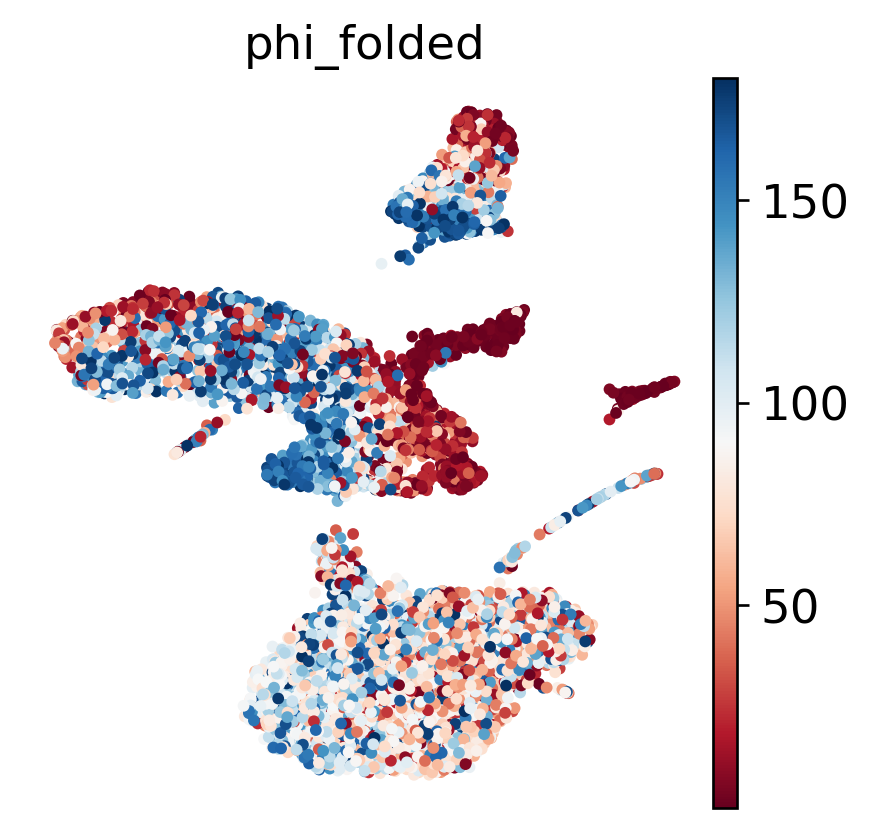

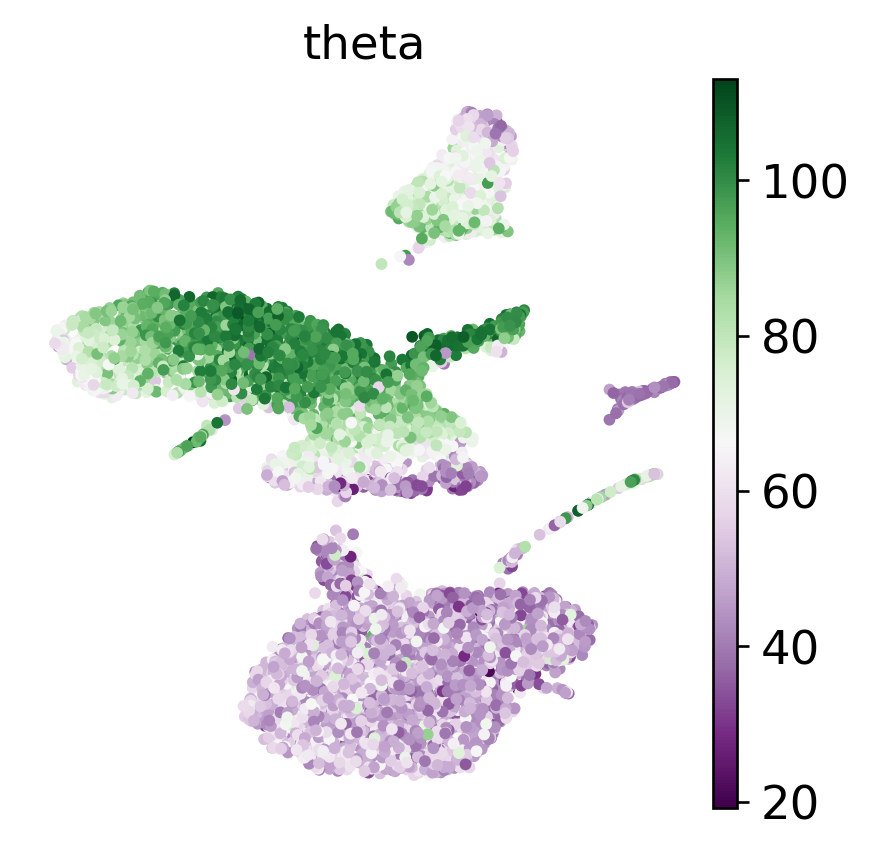

In [ ]:
from matplotlib import colorbar
sc.set_figure_params(figsize=(4, 4), dpi=120)

#ax1 = sc.pl.umap(adata_all, s=50, color=['phi_folded'], cmap='RdBu', frameon=False, alpha=0.8, sort_order=False, show=False, colorbar_loc=None)
ax1b = sc.pl.umap(adata_all, s=50, color=['phi_folded'], cmap='RdBu', frameon=False, alpha=1, sort_order=False, show=False)
#ax2 = sc.pl.umap(adata_all, s=50, color=['theta'], cmap='PRGn', frameon=False, alpha=0.8, sort_order=False, show=False, colorbar_loc=None)
ax2b = sc.pl.umap(adata_all, s=50, color=['theta'], cmap='PRGn', frameon=False, alpha=1, sort_order=False, show=False)

#ax1.figure.savefig(base_path+'figs/'+'YSL_subset_phi.png', dpi=200, bbox_inches="tight")
#ax1b.figure.savefig(base_path+'figs/'+'YSL_subset_phi.pdf', dpi=200, bbox_inches="tight")
#ax2.figure.savefig(base_path+'figs/'+'YSL_subset_theta.png', dpi=200, bbox_inches="tight")
#ax2b.figure.savefig(base_path+'figs/'+'YSL_subset_theta.pdf', dpi=200, bbox_inches="tight")


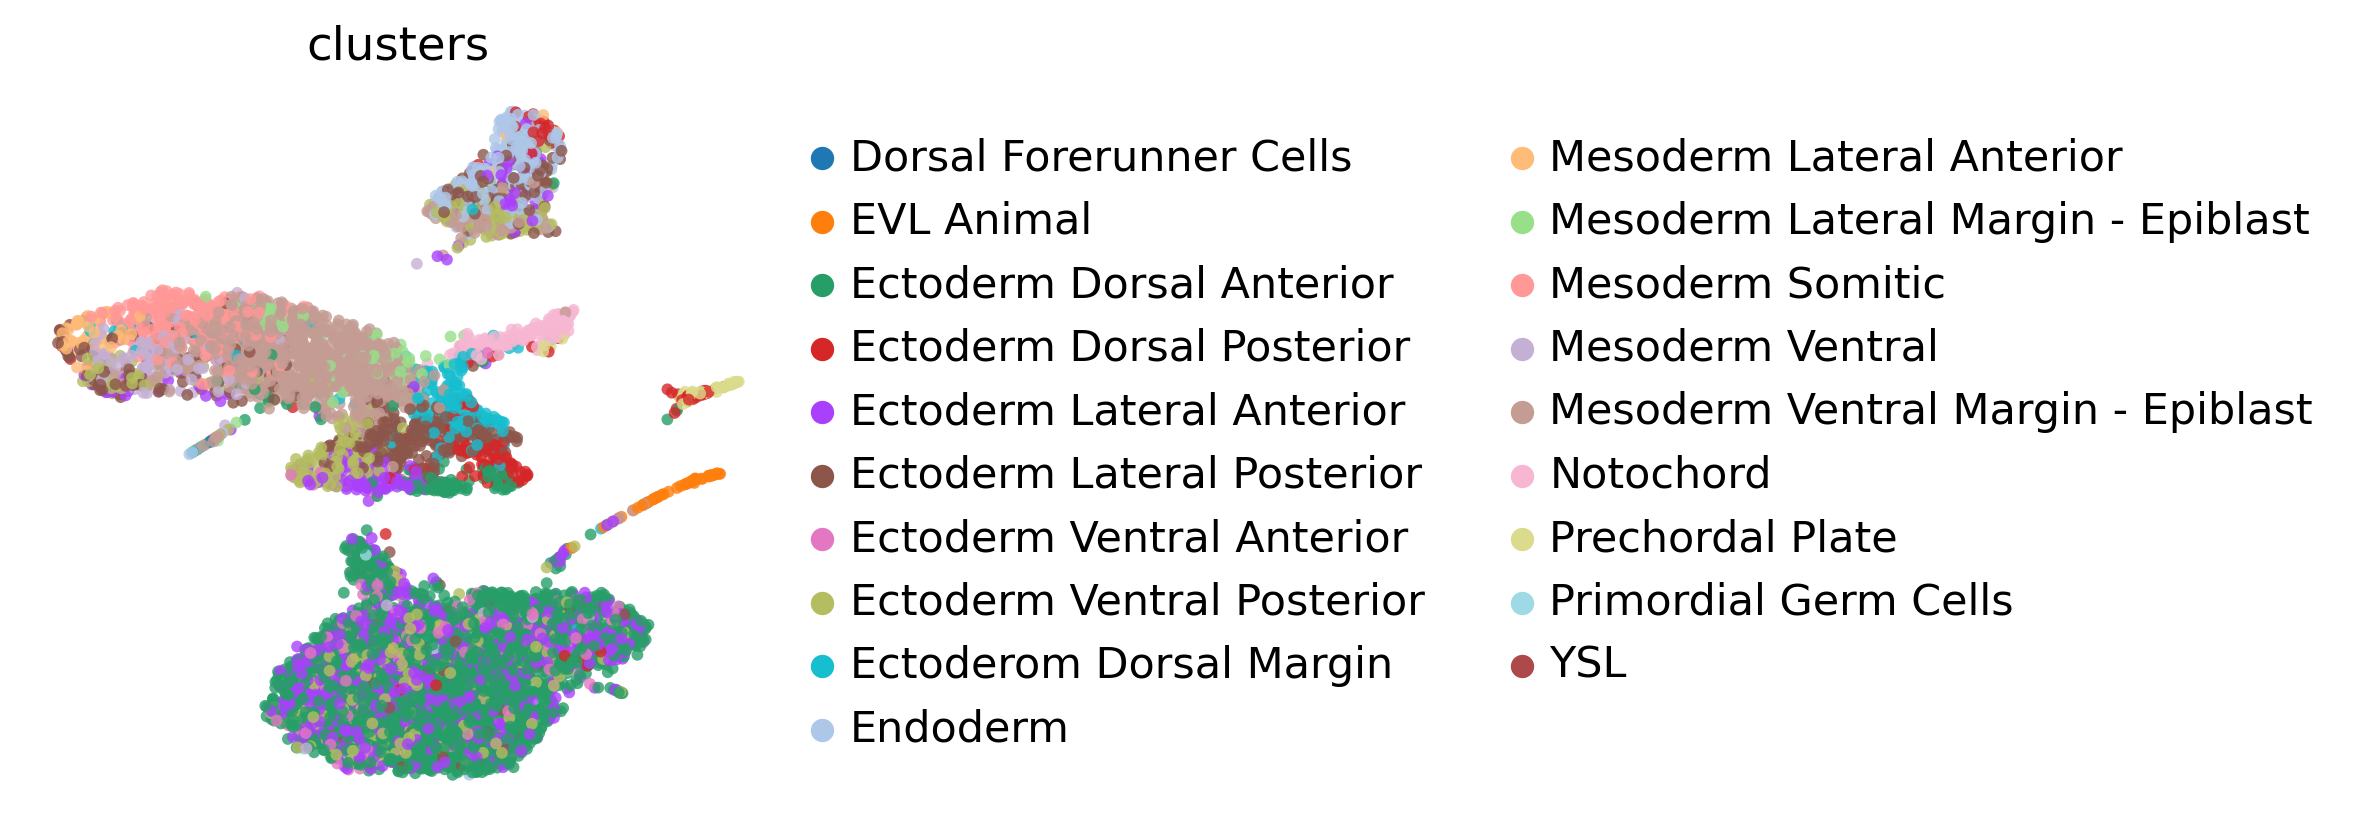

In [ ]:
ax1 = sc.pl.umap(adata_all, s=50, color=['clusters'], cmap='RdBu', frameon=False, alpha=0.8, sort_order=False, show=False, colorbar_loc=None)


In [ ]:
adata_all.write(base_path+'YSL-full_pp_norm_processed.h5ad')

## Run pipeline (YSL vs YSL)

In [ ]:
# Need to reload the unmodified MERFISH adata for the annotation pipeline
adata_mf1 = sc.read('/content/drive/MyDrive/Colab Notebooks/WanSchier2026/weMERFISH_measured_B_75p_E1.h5ad')
adata_mf2 = sc.read('/content/drive/MyDrive/Colab Notebooks/WanSchier2026/weMERFISH_measured_B_75p_E2.h5ad')

# For this run, subset to just the YSL
adata_mf = adata_mf1.concatenate(adata_mf2)
adata_mf.layers['raw_nolog'] = adata_mf.X.copy()
adata_mf_ysl = adata_mf[adata_mf.obs['clusters']=='YSL']


/tmp/ipykernel_41632/3238209650.py:4: FutureWarning: The method concatenate is deprecated and will be removed in the future. Use anndata.concat instead of AnnData.concatenate. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata_mf = adata_mf1.concatenate(adata_mf2)


In [ ]:
ref = adata_mf_ysl
query = adata

ref, query = run_pipeline(
    ref, query,
    raw_layer='raw_nolog',
    cat_keys='clusters',
    num_keys=['phi', 'theta'],
    circular_keys='phi',
    circular_period=360,
    circular_range='centered',
    fold_keys='phi',
    fold_axis=0,
    calibrate_keys=None,
    n_pcs=50, k=10,
)

Reference: 892 cells | 495 genes | Harmony on
Query: 4,823 cells | 495 genes
Done.


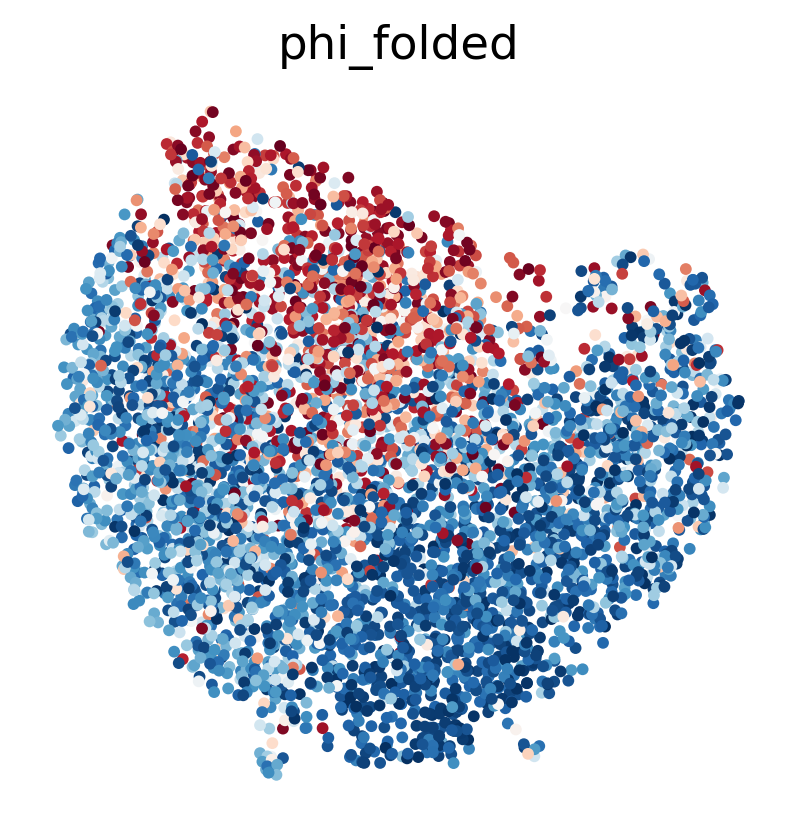

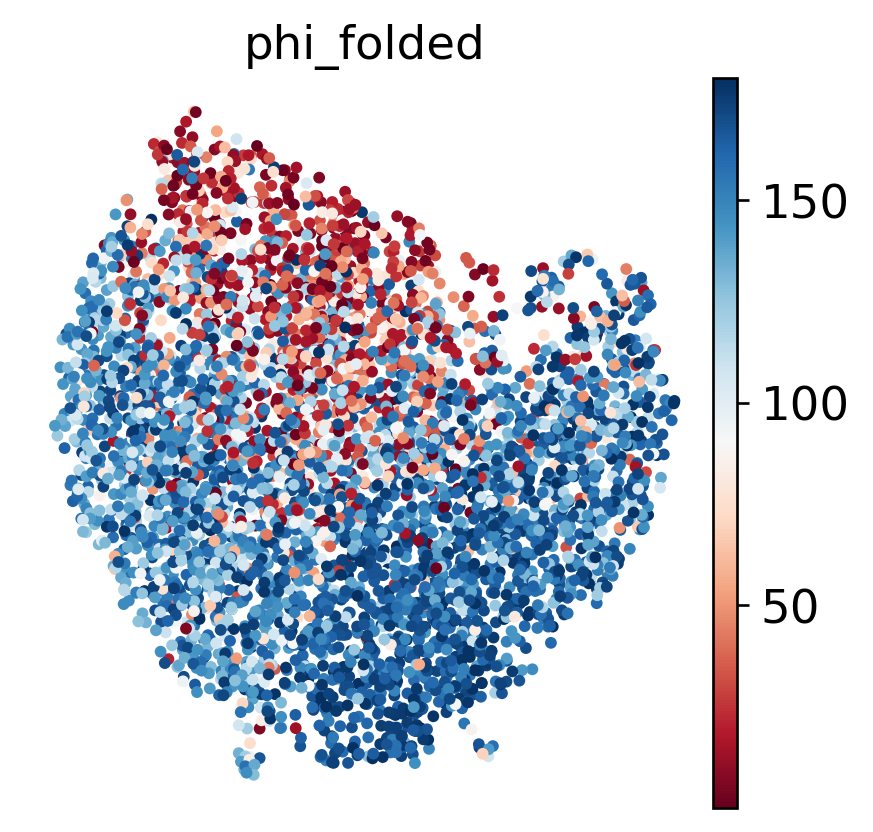

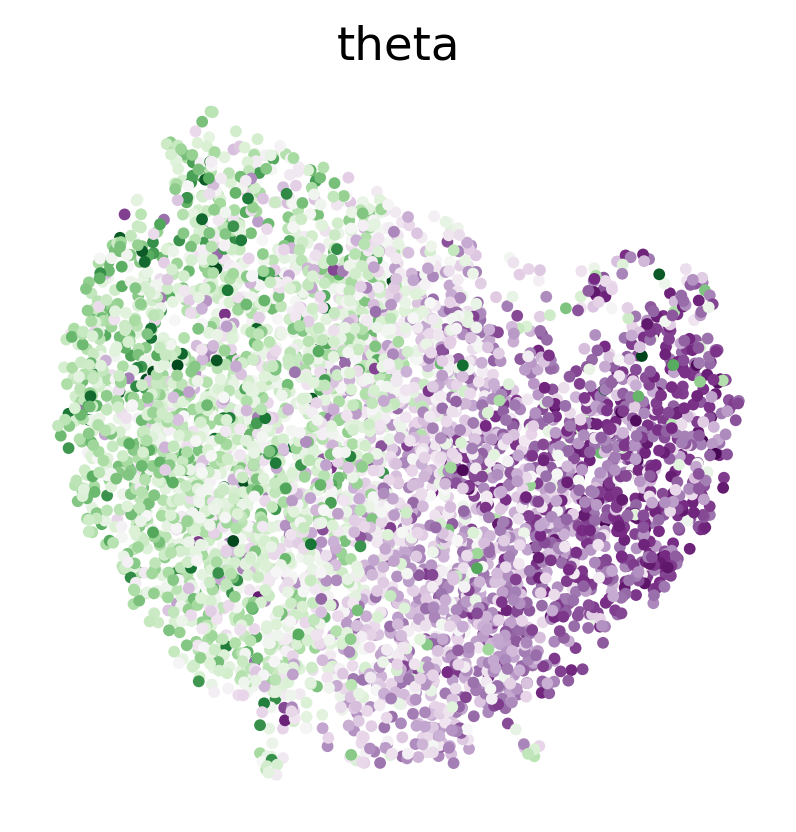

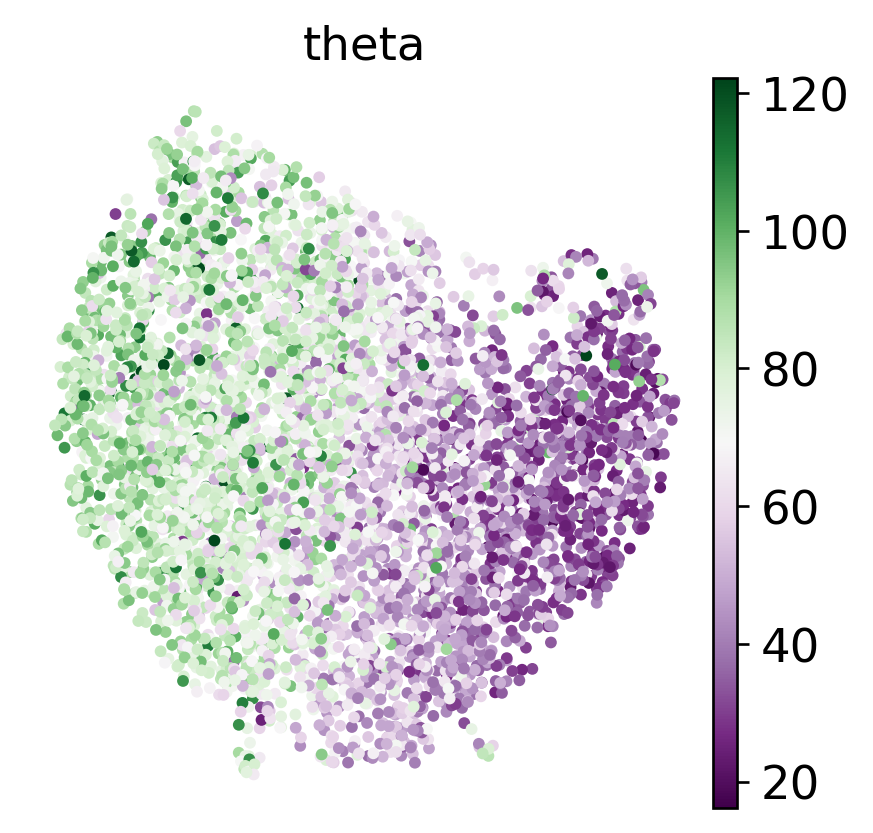

In [ ]:
from matplotlib import colorbar
sc.set_figure_params(figsize=(4, 4), dpi=120)

ax1 = sc.pl.umap(adata, s=50, color=['phi_folded'], cmap='RdBu', frameon=False, alpha=1, sort_order=False, show=False, colorbar_loc=None)
ax1b = sc.pl.umap(adata, s=50, color=['phi_folded'], cmap='RdBu', frameon=False, alpha=1, sort_order=False, show=False)
ax2 = sc.pl.umap(adata, s=50, color=['theta'], cmap='PRGn', frameon=False, alpha=1, sort_order=False, show=False, colorbar_loc=None)
ax2b = sc.pl.umap(adata, s=50, color=['theta'], cmap='PRGn', frameon=False, alpha=1, sort_order=False, show=False)

#ax1.figure.savefig(base_path+'figs/'+'YSL_subset_phi.png', dpi=200, bbox_inches="tight")
#ax1b.figure.savefig(base_path+'figs/'+'YSL_subset_phi.pdf', dpi=200, bbox_inches="tight")
#ax2.figure.savefig(base_path+'figs/'+'YSL_subset_theta.png', dpi=200, bbox_inches="tight")
#ax2b.figure.savefig(base_path+'figs/'+'YSL_subset_theta.pdf', dpi=200, bbox_inches="tight")


In [ ]:
adata.write(base_path+'YSL-subset_pp_norm_processed.h5ad')